<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [VGI Hydrology Worker](https://github.com/Query-farm/vgi-hydrology)

Upstream catchments and land-cover summaries for monitoring stations.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-hydrology/blob/main/notebooks/01_compare_upstream_catchments.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-hydrology/blob/main/notebooks/README.md)


## 01 · How much upstream area depends on where the station lands?

A monitoring point can fall beside the drainage channel. We delineate its upstream
catchment, compare it with two reference stations, then summarize the land cover and
synthetic facilities contained by each polygon. A focused snapping experiment shows
how a small position change can alter the selected upstream area.

The inputs are **synthetic**: a 7 × 7 DEM and matching categorical raster copied
unchanged from this worker's published test fixtures. Cells are 10 m × 10 m in
EPSG:32618; horizontal coordinates and elevations use metres. Class codes 10 and 20
are toy categories, not a real land-use inventory. Python renders the results;
the real published worker performs depression-filled D8 routing and polygonization,
and visible SQL handles joins, comparisons and area checks.

This is upstream drainage geometry. It does not model flooding, pollutant transport
or facility impact. A catchment reaching the DEM boundary may continue beyond the
available raster. Nested station catchments overlap and must not be added as if they
were disjoint land parcels.

### Change the snapping radius

SNAP_RADIUS_M accepts finite numbers from 0 through 30 metres. Zero uses the station's
containing cell and does not apply a stream threshold. A positive radius selects the
nearest cell whose upstream area is at least 1,000 m², provided it lies within that
Euclidean radius. It is not a downstream path search. Restart and run all after editing.

In [1]:
SNAP_RADIUS_M = 0.0

### Run this notebook

Read the saved outputs on GitHub or use **Open in Colab**, then Run All. The base shared
package preserves compatible preloaded plotting/data libraries. Initial packages,
companions, extension and released Git worker need internet; analytical inputs are
synthetic and local. The worker's separate environment supplies its declared Python
and GIS dependencies. PyFlwDir's first JIT compilation can take longer than later runs.

No local source checkout or real API credentials are required. Actual hosted Colab is
not claimed; a fresh preloaded Python 3.12 notebook-only execution tests the same
installation, verified-companion and released-launch path.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.26":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.26"
if "rasterio" not in installed:
    %pip install -q "rasterio>=1.4,<2"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.26":
    raise RuntimeError("Install shared tools v0.3.26, then restart and run all.")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks.bootstrap import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("hydrology")
%matplotlib inline
theme()
session = connect(globals())
con = session.connection

import math

import rasterio
from matplotlib.patches import Polygon

if (
    type(SNAP_RADIUS_M) not in (int, float)
    or not math.isfinite(SNAP_RADIUS_M)
    or not 0 <= SNAP_RADIUS_M <= 30
):
    raise ValueError("SNAP_RADIUS_M must be a finite number from 0 through 30 metres")
source = "Synthetic 7 × 7 fixtures · 10 m cells · EPSG:32618 · Released hydrology v0.1.0"
basins = cover = checks = pd.DataFrame()

### Attach the released hydrology worker

The literal Git-tag launcher installs public release v0.1.0 in an isolated environment.
Only uv and this notebook directory are needed; no local worker build is consulted.
Spatial operates on returned WKB polygons for geometric checks and joins.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL spatial;
LOAD spatial;
ATTACH 'hydrology' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-hydrology@v0.1.0 vgi-hydrology-worker');
SELECT function_name FROM duckdb_functions()
WHERE database_name = 'hydrology' AND schema_name = 'main'
ORDER BY function_name;

,function_name
0,catchments
1,demo_input
2,landcover


### Keep reference and outside stations in the population

Retain the worker's bundled outlet station, add an upstream point and a point 10 m
east of it, plus a deliberately outside station. Their IDs are the join keys. The
three toy facilities use the same CRS. Inclusion means polygon coverage only;
it does not establish a hydrological or environmental effect.

In [5]:
%%sql
CREATE TABLE stations AS
SELECT station_id, x, y FROM hydrology.main.demo_input
UNION ALL SELECT * FROM (VALUES
    ('midstream', 500035.0, 4100035.0),
    ('offset', 500045.0, 4100035.0),
    ('outside', 500095.0, 4100055.0)
) AS t(station_id, x, y);
CREATE TABLE facilities AS SELECT * FROM (VALUES
    ('north-site', 500015.0, 4100055.0),
    ('east-site', 500055.0, 4100045.0),
    ('outside-site', 500095.0, 4100055.0)
) AS t(facility_id, x, y);
SELECT * FROM stations ORDER BY station_id;

,station_id,x,y
0,midstream,500035.0,4100035.0
1,offset,500045.0,4100035.0
2,outlet,500035.0,4100005.0
3,outside,500095.0,4100055.0


### Compare a fixed baseline with the selected policy

Materialize a fixed containing-cell baseline and the selected policy. Both use the
same DEM and 1,000-cell resource cap. A failed status retains the input identity but
has no area or polygon; its zero cell counter must not be mistaken for a measured
zero-area catchment. Display queries reuse these results without rerouting.

In [6]:
%%sql
CREATE TABLE baseline AS
SELECT * FROM hydrology.main.catchments((SELECT * FROM stations),
    dem := 'fixtures/basin.tif', input_crs := 'EPSG:32618', max_cells := 1000,
    snap_radius_m := 0.0, min_stream_area_m2 := 1000.0);
CREATE TABLE catchments AS
SELECT * FROM hydrology.main.catchments((SELECT * FROM stations),
    dem := 'fixtures/basin.tif', input_crs := 'EPSG:32618', max_cells := 1000,
    snap_radius_m := {{ SNAP_RADIUS_M }}, min_stream_area_m2 := 1000.0);
SELECT c.station_id, c.status, b.area_m2 AS containing_cell_area_m2,
    c.area_m2 AS selected_area_m2, c.area_m2 - b.area_m2 AS area_change_m2,
    c.snap_distance_m, c.boundary_limited
FROM catchments c JOIN baseline b USING (station_id) ORDER BY station_id;

,station_id,status,containing_cell_area_m2,selected_area_m2,area_change_m2,snap_distance_m,boundary_limited
0,midstream,ok,1600.0,1600.0,0.0,0.0,True
1,offset,ok,300.0,300.0,0.0,0.0,True
2,outlet,ok,4900.0,4900.0,0.0,0.0,True
3,outside,outside_dem,NaN,NaN,NaN,NaN,<NA>


In [7]:
%%sql basins <<
SELECT c.*, s.x AS input_x, s.y AS input_y,
    ST_AsGeoJSON(ST_GeomFromWKB(c.geometry_wkb)) AS geometry_geojson,
    b.area_m2 AS baseline_area_m2
FROM catchments c JOIN stations s USING (station_id) JOIN baseline b USING (station_id)
ORDER BY station_id;

In [8]:
successful = basins[basins.status == "ok"]
offset = basins.loc[basins.station_id == "offset"].iloc[0]
flagged = int(successful.boundary_limited.sum())
if offset.status == "ok":
    prose(
        f"With a **{SNAP_RADIUS_M:g} m** radius, the offset station selects **{offset.area_m2:,.0f} m²**, "
        f"compared with **{offset.baseline_area_m2:,.0f} m²** under the containing-cell policy. "
        f"Its selected cell centre is **{offset.snap_distance_m:g} m** from the input point. "
        f"**{flagged} of {len(successful)}** successful basins touch the raster boundary; "
        "their full upstream extent is not established by this small DEM."
    )
else:
    prose(
        f"The offset station has status **{offset.status}** at radius {SNAP_RADIUS_M:g} m. "
        "No area or polygon is available for its land-cover or facility analysis. "
        f"{flagged} of {len(successful)} successful reference basins touch the DEM boundary."
    )

With a **0 m** radius, the offset station selects **300 m²**, compared with **300 m²** under the containing-cell policy. Its selected cell centre is **0 m** from the input point. **3 of 3** successful basins touch the raster boundary; their full upstream extent is not established by this small DEM.

### Inspect the selected outlets and upstream polygons

Inspect the returned polygons against the elevation grid. Stars mark supplied
station locations; hollow circles mark selected outlet cells. Coincident catchments
are allowed: two station IDs can select the same channel cell. The outside station
stays outside the DEM even when snapping is enabled.

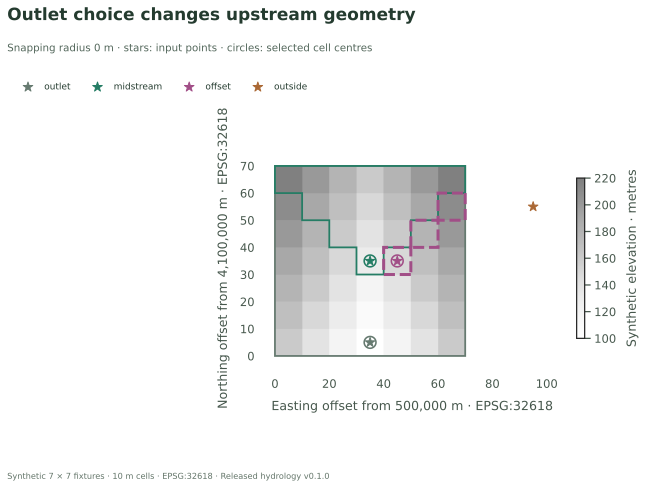

In [9]:
colors = {"outlet": "#667A70", "midstream": "#257D65", "offset": "#A14E87", "outside": "#AA6834"}
fig, ax = plt.subplots(figsize=(10.3, 7.2))
with rasterio.open("fixtures/basin.tif") as raster:
    image = ax.imshow(raster.read(1), extent=(0, 70, 0, 70), origin="upper", cmap="Greys", alpha=0.5)
    assert raster.crs.to_string() == "EPSG:32618" and raster.res == (10, 10)
bar = fig.colorbar(image, ax=ax, shrink=0.72, pad=0.025)
bar.set_label("Synthetic elevation · metres")
for name in ["outlet", "midstream", "offset", "outside"]:
    row = basins.loc[basins.station_id == name].iloc[0]
    color = colors[name]
    if row.status == "ok":
        geometry = json.loads(row.geometry_geojson)
        polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
        for polygon in polygons:
            coordinates = np.asarray(polygon[0]) - np.array([500000, 4100000])
            ax.add_patch(
                Polygon(
                    coordinates,
                    fill=False,
                    edgecolor=color,
                    linewidth=3 if name == "offset" else 1.8,
                    linestyle="--" if name == "offset" else "-",
                )
            )
        ax.plot(
            [row.input_x - 500000, row.outlet_x - 500000],
            [row.input_y - 4100000, row.outlet_y - 4100000],
            color=color,
            linewidth=1.4,
        )
        ax.scatter(
            row.outlet_x - 500000,
            row.outlet_y - 4100000,
            s=140,
            facecolor="none",
            edgecolor=color,
            linewidth=1.6,
        )
    ax.scatter(row.input_x - 500000, row.input_y - 4100000, marker="*", s=100, color=color, label=name)
ax.set(
    xlim=(-4, 105),
    ylim=(-5, 77),
    aspect="equal",
    xlabel="Easting offset from 500,000 m · EPSG:32618",
    ylabel="Northing offset from 4,100,000 m · EPSG:32618",
)
fig.legend(
    *ax.get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.075, 0.84), ncol=4, fontsize=9
)
finish(
    fig,
    "Outlet choice changes upstream geometry",
    f"Snapping radius {SNAP_RADIUS_M:g} m · stars: input points · circles: selected cell centres",
    source,
    name=f"upstream-map-{SNAP_RADIUS_M:g}",
)

### Separate land-cover composition from coverage

Feed only successful catchments into the categorical summarizer. We retain the
worker's coverage fraction separately from class composition: class shares describe
valid observed pixels, while coverage describes how much of the polygon was observed.
The fixture rasters align exactly, so class area can be reconciled with DEM area.

In [10]:
%%sql
CREATE TABLE land_cover AS
SELECT * FROM hydrology.main.landcover(
    (SELECT station_id, geometry_wkb FROM catchments WHERE status = 'ok'),
    raster := 'fixtures/landcover.tif', geometry_crs := 'EPSG:32618', max_pixels := 1000);
SELECT station_id, class_code, pixel_count, area_m2,
    round(100 * fraction_of_valid, 2) AS percent_of_valid,
    round(100 * coverage_fraction, 2) AS percent_coverage, status
FROM land_cover ORDER BY station_id, class_code;

,station_id,class_code,pixel_count,area_m2,percent_of_valid,percent_coverage,status
0,midstream,10,6,600.0,37.50,100.0,ok
1,midstream,20,10,1000.0,62.50,100.0,ok
2,offset,20,3,300.0,100.00,100.0,ok
3,outlet,10,21,2100.0,42.86,100.0,ok
4,outlet,20,28,2800.0,57.14,100.0,ok


In [11]:
%%sql cover <<
SELECT station_id, class_code, area_m2, fraction_of_valid, coverage_fraction
FROM land_cover ORDER BY station_id, class_code;

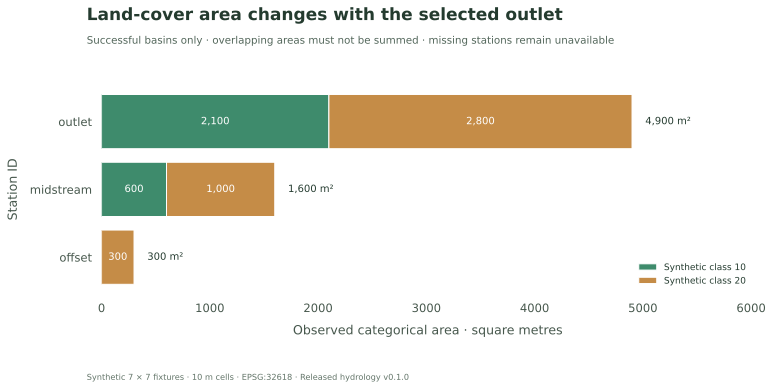

In [12]:
ids = [name for name in ["outlet", "midstream", "offset"] if name in set(successful.station_id)]
fig, ax = plt.subplots(figsize=(10.3, 5.7))
left = np.zeros(len(ids))
for class_code, color in [(10, "#3E8B6C"), (20, "#C58C47")]:
    values = np.array(
        [
            cover.loc[(cover.station_id == name) & (cover.class_code == class_code), "area_m2"].sum()
            for name in ids
        ],
        dtype=float,
    )
    ax.barh(ids, values, left=left, color=color, label=f"Synthetic class {class_code}")
    for i, value in enumerate(values):
        if value > 0:
            ax.text(
                left[i] + value / 2, i, f"{value:,.0f}", ha="center", va="center", color="white", fontsize=10
            )
    left += values
for i, total in enumerate(left):
    ax.text(total + max(left) * 0.025, i, f"{total:,.0f} m²", va="center", fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0, max(left) * 1.23)
ax.set_xlabel("Observed categorical area · square metres")
ax.set_ylabel("Station ID")
ax.legend(loc="lower right", fontsize=9)
finish(
    fig,
    "Land-cover area changes with the selected outlet",
    "Successful basins only · overlapping areas must not be summed · missing stations remain unavailable",
    source,
    name=f"land-cover-{SNAP_RADIUS_M:g}",
)

### Join facility identities without assuming containment is causal

Finally join synthetic facility points to each successful basin with ST_Covers.
The same facility may appear for several nested basins. A separate left-joined
summary distinguishes no covered facilities from an unavailable catchment.

A larger snapping radius can choose another drainage cell; a larger selected basin
does not guarantee that the previous set of covered facilities is retained. Compare
facility identities as well as counts.

In [13]:
%%sql
CREATE TABLE covered_facilities AS
SELECT c.station_id, f.facility_id
FROM catchments c JOIN facilities f
ON c.status = 'ok' AND ST_Covers(ST_GeomFromWKB(c.geometry_wkb), ST_Point(f.x, f.y));
SELECT c.station_id, c.status,
    CASE WHEN c.status = 'ok' THEN count(f.facility_id) END AS covered_facility_count,
    string_agg(f.facility_id, ', ' ORDER BY f.facility_id) AS facility_ids
FROM catchments c LEFT JOIN covered_facilities f USING (station_id)
GROUP BY c.station_id, c.status ORDER BY c.station_id;

,station_id,status,covered_facility_count,facility_ids
0,midstream,ok,1,north-site
1,offset,ok,1,east-site
2,outlet,ok,2,"east-site, north-site"
3,outside,outside_dem,<NA>,None


In [14]:
%%sql checks <<
SELECT 'One result per supplied station' AS invariant,
    count(*) = (SELECT count(*) FROM stations) AND count(*) = count(DISTINCT station_id) AS passed FROM catchments
UNION ALL SELECT 'Successful area equals 100 m² per DEM cell', bool_and(abs(area_m2 - cell_count * 100) < 1e-8)
    FROM catchments WHERE status = 'ok'
UNION ALL SELECT 'WKB polygon area agrees with raster cells', bool_and(abs(ST_Area(ST_GeomFromWKB(geometry_wkb)) - area_m2) < 1e-8)
    FROM catchments WHERE status = 'ok'
UNION ALL SELECT 'Failed catchments have NULL area and geometry', bool_and(area_m2 IS NULL AND geometry_wkb IS NULL)
    FROM catchments WHERE status <> 'ok'
UNION ALL SELECT 'Geometry CRS is explicit', bool_and(dem_crs = 'EPSG:32618') FROM catchments
UNION ALL SELECT 'Positive snapping stays within radius',
    bool_and({{ SNAP_RADIUS_M }} = 0 OR snap_distance_m <= {{ SNAP_RADIUS_M }} + 1e-8)
    FROM catchments WHERE status = 'ok'
UNION ALL SELECT 'Positive snapping meets drainage threshold',
    bool_and({{ SNAP_RADIUS_M }} = 0 OR area_m2 >= 1000) FROM catchments WHERE status = 'ok'
UNION ALL SELECT 'Boundary incompleteness remains visible', bool_and(boundary_limited)
    FROM catchments WHERE status = 'ok'
UNION ALL SELECT 'Nested reference basins remain complete',
    ST_Covers(ST_GeomFromWKB(d.geometry_wkb), ST_GeomFromWKB(u.geometry_wkb)) AND d.area_m2 > u.area_m2
    FROM catchments d, catchments u WHERE d.station_id = 'outlet' AND u.station_id = 'midstream'
UNION ALL SELECT 'Class areas conserve each successful catchment', bool_and(abs(l.total - c.area_m2) < 1e-8)
    FROM catchments c JOIN (SELECT station_id, sum(area_m2) AS total FROM land_cover GROUP BY station_id) l USING (station_id)
UNION ALL SELECT 'Aligned fixture coverage is complete', bool_and(coverage_fraction = 1 AND status = 'ok') FROM land_cover
UNION ALL SELECT 'Class shares sum to one per catchment', bool_and(abs(total - 1) < 1e-8)
    FROM (SELECT station_id, sum(fraction_of_valid) AS total FROM land_cover GROUP BY station_id);

In [15]:
display(checks)
assert len(checks) == 12 and checks.passed.all()
prose(
    f"All **{len(checks)} checks** pass: geometry, raster area and class shares agree, "
    "failed stations remain unavailable, and nested basins retain their full upstream area. "
    "The boundary flag is still true; internal consistency does not establish a complete real watershed."
)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/catchment-audit.json").write_text(
    json.dumps(
        {
            "snap_radius_m": SNAP_RADIUS_M,
            "basins": basins.drop(columns=["geometry_wkb"]).to_dict("records"),
            "land_cover": cover.to_dict("records"),
            "facilities": con.execute("SELECT * FROM covered_facilities ORDER BY station_id,facility_id")
            .fetchdf()
            .to_dict("records"),
            "baseline": con.execute(
                "SELECT station_id,status,area_m2,outlet_x,outlet_y FROM baseline ORDER BY station_id"
            )
            .fetchdf()
            .to_dict("records"),
            "checks": checks.to_dict("records"),
        },
        indent=2,
    )
)

,invariant,passed
0,One result per supplied station,True
1,Successful area equals 100 m² per DEM cell,True
2,WKB polygon area agrees with raster cells,True
3,Failed catchments have NULL area and geometry,True
4,Geometry CRS is explicit,True
5,Positive snapping stays within radius,True
6,Positive snapping meets drainage threshold,True
7,Boundary incompleteness remains visible,True
8,Nested reference basins remain complete,True
9,Class areas conserve each successful catchment,True


All **12 checks** pass: geometry, raster area and class shares agree, failed stations remain unavailable, and nested basins retain their full upstream area. The boundary flag is still true; internal consistency does not establish a complete real watershed.

5419

### Experiment: reach the neighboring channel cell

**Focused experiment.** Change SNAP_RADIUS_M from 0.0 to 15.0 and run all in a
separate copy. Predict whether the offset station can reach an eligible channel cell.
Compare its selected outlet, area, class composition and covered facilities; inspect
whether its polygon now coincides with the midstream basin. The containing-cell
baseline, raster bytes and other station coordinates remain fixed. This tests one
geometric policy, not a uniquely correct real-world station location. Restore 0.0
for the saved default. README.md contains the exact experiment command.

In [16]:
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-hydrology](https://github.com/Query-farm/vgi-hydrology)
